#**Практическое задание №1**

In [ ]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
Tesla T4


Установка необходимых пакетов:

In [ ]:
!pip install -q tqdm
!pip install --upgrade --no-cache-dir gdown

Монтирование Вашего Google Drive к текущему окружению:

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


Константы, которые пригодятся в коде далее, и ссылки (gdrive идентификаторы) на предоставляемые наборы данных:

In [ ]:
EVALUATE_ONLY = False
TEST_ON_LARGE_DATASET = True
TISSUE_CLASSES = ('ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM')
DATASETS_LINKS = {
    'train': '1XtQzVQ5XbrfxpLHJuL0XBGJ5U7CS-cLi',
    'train_small': '1qd45xXfDwdZjktLFwQb-et-mAaFeCzOR',
    'train_tiny': '1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui',
    'test': '1RfPou3pFKpuHDJZ-D9XDFzgvwpUBFlDr',
    'test_small': '1wbRsog0n7uGlHIPGLhyN-PMeT2kdQ2lI',
    'test_tiny': '1viiB0s041CNsAK4itvX8PnYthJ-MDnQc'
}


Импорт необходимых зависимостей:

In [ ]:
from pathlib import Path
import numpy as np
from typing import List
from tqdm.notebook import tqdm
from time import sleep
from PIL import Image
import IPython.display
from sklearn.metrics import balanced_accuracy_score
import gdown

---
### Класс Dataset

Предназначен для работы с наборами данных, обеспечивает чтение изображений и соответствующих меток, а также формирование пакетов (батчей).

In [ ]:
class Dataset:

    def __init__(self, name):
        self.name = name
        self.is_loaded = False
        url = f"https://drive.google.com/uc?export=download&confirm=pbef&id={DATASETS_LINKS[name]}"
        output = f'{name}.npz'
        gdown.download(url, output, quiet=False)
        print(f'Loading dataset {self.name} from npz.')
        np_obj = np.load(f'{name}.npz')
        self.images = np_obj['data']
        self.labels = np_obj['labels']
        self.n_files = self.images.shape[0]
        self.is_loaded = True
        print(f'Done. Dataset {name} consists of {self.n_files} images.')

    def image(self, i):
        # read i-th image in dataset and return it as numpy array
        if self.is_loaded:
            return self.images[i, :, :, :]

    def images_seq(self, n=None):
        # sequential access to images inside dataset (is needed for testing)
        for i in range(self.n_files if not n else n):
            yield self.image(i)

    def random_image_with_label(self):
        # get random image with label from dataset
        i = np.random.randint(self.n_files)
        return self.image(i), self.labels[i]

    def random_batch_with_labels(self, n):
        # create random batch of images with labels (is needed for training)
        indices = np.random.choice(self.n_files, n)
        imgs = [self.image(i) for i in indices]
        labels = np.array([self.labels[i] for i in indices])
        return np.stack(imgs), labels

    def image_with_label(self, i: int):
        # return i-th image with label from dataset
        return self.image(i), self.labels[i]


### Пример использвания класса Dataset
Загрузим обучающий набор данных, получим произвольное изображение с меткой. После чего визуализируем изображение, выведем метку. В будущем, этот кусок кода можно закомментировать или убрать.

Downloading...
From (original): https://drive.google.com/uc?id=1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui
From (redirected): https://drive.google.com/uc?id=1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui&confirm=t&uuid=9c5b56f1-2189-4526-bd24-f6e91ee92f1a
To: /content/train_tiny.npz
100%|██████████| 105M/105M [00:00<00:00, 108MB/s] 


Loading dataset train_tiny from npz.
Done. Dataset train_tiny consists of 900 images.

Got numpy array of shape (224, 224, 3), and label with code 0.
Label code corresponds to ADI class.


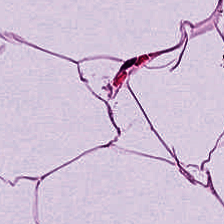

In [ ]:
d_train_tiny = Dataset('train_tiny')

img, lbl = d_train_tiny.random_image_with_label()
print()
print(f'Got numpy array of shape {img.shape}, and label with code {lbl}.')
print(f'Label code corresponds to {TISSUE_CLASSES[lbl]} class.')

pil_img = Image.fromarray(img)
IPython.display.display(pil_img)

### Обёртка над Dataset для использования с PyTorch

In [ ]:
# ============================================================
# (Опционально) Обёртка над Dataset для использования с PyTorch
# ============================================================

# ВНИМАНИЕ:
# Этот код нужен только тем, кто хочет решать задание с помощью PyTorch.
# Он показывает, как "подключить" наш Dataset к torch.utils.data.DataLoader.

try:
    import torch
    from torch.utils.data import Dataset as TorchDataset, DataLoader
    import torchvision.transforms as T
    from PIL import Image

    class HistologyTorchDataset(TorchDataset):
        """
        Обёртка над Dataset для использования с PyTorch.

        base_dataset: экземпляр Dataset('train'), Dataset('train_small'), etc.
        transform:    функция/объект, преобразующий изображение (PIL.Image -> torch.Tensor).

        """
        def __init__(self, base_dataset, transform=None):
            self.base = base_dataset
            # Минимальный transform по умолчанию:
            # np.uint8 [0, 255] -> float32 [0.0, 1.0]
            self.transform = transform or T.ToTensor()

        def __len__(self):
            # Размер датасета
            return len(self.base.images)

        def __getitem__(self, idx):
            """
            Возвращает (image_tensor, label) для PyTorch.
            image_tensor: torch.Tensor формы [3, H, W]
            label: int
            """
            img, label = self.base.image_with_label(idx)  # img: np.ndarray (H, W, 3)
            img = Image.fromarray(img)                    # в PIL.Image
            img = self.transform(img)                     # в torch.Tensor
            return img, int(label)

except ImportError:
    HistologyTorchDataset = None
    print("PyTorch / torchvision не найдены. Обёртка HistologyTorchDataset недоступна.")


### Пример использвания класса HistologyTorchDataset

In [ ]:
if "HistologyTorchDataset" not in globals() or HistologyTorchDataset is None:
    print("PyTorch не установлен или обёртка недоступна — пример пропущен.")
else:
    print("Пример использования PyTorch-обёртки над Dataset")

    base_train = Dataset('train_tiny')

    # Создаём PyTorch-совместимый датасет
    train_ds = HistologyTorchDataset(base_train)

    # DataLoader автоматически создаёт батчи и перемешивает данные
    from torch.utils.data import DataLoader
    train_loader = DataLoader(train_ds, batch_size=8, shuffle=True)

    # Берём один батч и выводим информацию
    images_batch, labels_batch = next(iter(train_loader))

    print("Форма батча изображений:", tuple(images_batch.shape))  # [batch, 3, 224, 224]
    print("Форма батча меток:", tuple(labels_batch.shape))        # [batch]
    print("Пример меток:", labels_batch[:10].tolist())

    print("Тип images_batch:", type(images_batch))
    print("Тип labels_batch:", type(labels_batch))


Пример использования PyTorch-обёртки над Dataset


Downloading...
From (original): https://drive.google.com/uc?id=1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui
From (redirected): https://drive.google.com/uc?id=1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui&confirm=t&uuid=33c47edc-719a-4a40-9ccc-537563169ab6
To: /content/train_tiny.npz
100%|██████████| 105M/105M [00:00<00:00, 126MB/s] 


Loading dataset train_tiny from npz.
Done. Dataset train_tiny consists of 900 images.
Форма батча изображений: (8, 3, 224, 224)
Форма батча меток: (8,)
Пример меток: [8, 1, 0, 5, 7, 5, 0, 5]
Тип images_batch: <class 'torch.Tensor'>
Тип labels_batch: <class 'torch.Tensor'>


---
### Класс Metrics

Реализует метрики точности, используемые для оценивания модели:
1. точность,
2. сбалансированную точность.

In [ ]:
class Metrics:

    @staticmethod
    def accuracy(gt: List[int], pred: List[int]):
        assert len(gt) == len(pred), 'gt and prediction should be of equal length'
        return sum(int(i[0] == i[1]) for i in zip(gt, pred)) / len(gt)

    @staticmethod
    def accuracy_balanced(gt: List[int], pred: List[int]):
        return balanced_accuracy_score(gt, pred)

    @staticmethod
    def print_all(gt: List[int], pred: List[int], info: str):
        print(f'metrics for {info}:')
        print('\t accuracy {:.4f}:'.format(Metrics.accuracy(gt, pred)))
        print('\t balanced accuracy {:.4f}:'.format(Metrics.accuracy_balanced(gt, pred)))

---
### Класс Model

Класс, хранящий в себе всю информацию о модели.

Вам необходимо реализовать методы save, load для сохранения и загрузки модели. Особенно актуально это будет во время тестирования на дополнительных наборах данных.


> *Пожалуйста, убедитесь, что сохранение и загрузка модели работает корректно. Для этого обучите модель, протестируйте, сохраните ее в файл, перезапустите среду выполнения, загрузите обученную модель из файла, вновь протестируйте ее на тестовой выборке и убедитесь в том, что получаемые метрики совпадают с полученными для тестовой выборки ранее.*


Также, Вы можете реализовать дополнительные функции, такие как:
1. валидацию модели на части обучающей выборки;
2. использование кроссвалидации;
3. автоматическое сохранение модели при обучении;
4. загрузку модели с какой-то конкретной итерации обучения (если используется итеративное обучение);
5. вывод различных показателей в процессе обучения (например, значение функции потерь на каждой эпохе);
6. построение графиков, визуализирующих процесс обучения (например, график зависимости функции потерь от номера эпохи обучения);
7. автоматическое тестирование на тестовом наборе/наборах данных после каждой эпохи обучения (при использовании итеративного обучения);
8. автоматический выбор гиперпараметров модели во время обучения;
9. сохранение и визуализацию результатов тестирования;
10. Использование аугментации и других способов синтетического расширения набора данных (дополнительным плюсом будет обоснование необходимости и обоснование выбора конкретных типов аугментации)
11. и т.д.

Полный список опций и дополнений приведен в презентации с описанием задания.

При реализации дополнительных функций допускается добавление параметров в существующие методы и добавление новых методов в класс модели.


In [37]:
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as T
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt

class Model:

    def __init__(self):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        self.net = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        self.net.fc = nn.Linear(self.net.fc.in_features, 9)
        self.net = self.net.to(self.device)

        self.transform = T.Compose([
            T.ToTensor(),
            T.Normalize([0.485, 0.456, 0.406],
                        [0.229, 0.224, 0.225])
        ])

        self.train_transform = T.Compose([
            T.RandomHorizontalFlip(),
            T.RandomVerticalFlip(),
            T.ToTensor(),
            T.Normalize([0.485, 0.456, 0.406],
                        [0.229, 0.224, 0.225])
        ])

    # LBL1: сохранение весов
    def save(self, name: str):
        path = f'/content/drive/MyDrive/{name}.pth'
        torch.save(self.net.state_dict(), path)
        print(f'Модель сохранена: {path}')

    # LBL2: загрузка весов из Google Drive
    def load(self, name: str):
        file_ids = {
            'best': '1AG_w7pRI_CqgsFIo2cUwoL20zVaAZ5t_'
        }

        path = f'/content/{name}.pth'
        gdown.download(id=file_ids[name], output=path, quiet=False)

        state = torch.load(path, map_location=self.device, weights_only=True)
        self.net.load_state_dict(state)
        self.net.eval()

        print('Модель загружена')

    def train(self, dataset: Dataset):
        torch.manual_seed(42)

        full_data = HistologyTorchDataset(dataset)
        n_val = int(len(full_data) * 0.15)
        n_train = len(full_data) - n_val

        train_data, val_data = random_split(
            full_data, [n_train, n_val],
            generator=torch.Generator().manual_seed(42)
        )

        # LBL3: аугментация обучающих изображений
        train_data.dataset = HistologyTorchDataset(dataset, self.train_transform)
        val_data.dataset = HistologyTorchDataset(dataset, self.transform)

        train_loader = DataLoader(train_data, batch_size=64,
                                  shuffle=True, num_workers=2)
        val_loader = DataLoader(val_data, batch_size=64,
                                num_workers=2)

        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.AdamW(self.net.parameters(), lr=0.0001)

        train_losses = []
        val_accuracies = []
        best_acc = 0

        # LBL4: обучение с валидацией
        for epoch in range(8):
            self.net.train()
            total_loss = 0

            for images, labels in tqdm(train_loader, desc=f'Epoch {epoch + 1}/8'):
                images = images.to(self.device)
                labels = labels.to(self.device)

                optimizer.zero_grad()
                outputs = self.net(images)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()

                total_loss += loss.item() * len(images)

            train_loss = total_loss / n_train

            self.net.eval()
            correct = 0

            with torch.no_grad():
                for images, labels in val_loader:
                    images = images.to(self.device)
                    labels = labels.to(self.device)

                    outputs = self.net(images)
                    correct += (outputs.argmax(1) == labels).sum().item()

            val_acc = correct / n_val
            train_losses.append(train_loss)
            val_accuracies.append(val_acc)

            # LBL5: сохранение лучшей модели
            if val_acc > best_acc:
                best_acc = val_acc
                self.save('best')

            print(f'Epoch {epoch + 1}: loss={train_loss:.4f}, '
                  f'val_acc={val_acc:.4f}, best={best_acc:.4f}')

        # Возвращаем лучшие веса, а не последнюю эпоху
        self.load('best')

        # LBL6: графики обучения
        plt.figure(figsize=(10, 4))

        plt.subplot(1, 2, 1)
        plt.plot(train_losses)
        plt.title('Train loss')
        plt.xlabel('Epoch')

        plt.subplot(1, 2, 2)
        plt.plot(val_accuracies)
        plt.title('Validation accuracy')
        plt.xlabel('Epoch')

        plt.tight_layout()
        plt.show()

    def test_on_dataset(self, dataset: Dataset, limit=None):
        n = dataset.n_files if limit is None else int(dataset.n_files * limit)

        data = HistologyTorchDataset(dataset, self.transform)
        loader = DataLoader(
            torch.utils.data.Subset(data, range(n)),
            batch_size=64, num_workers=2
        )

        self.net.eval()
        predictions = []

        with torch.no_grad():
            for images, _ in tqdm(loader):
                outputs = self.net(images.to(self.device))
                predictions.extend(outputs.argmax(1).cpu().tolist())

        return predictions

    def test_on_image(self, img: np.ndarray, submission_year: int):
        self.net.eval()
        image = self.transform(Image.fromarray(img)).unsqueeze(0)
        image = image.to(self.device)

        with torch.no_grad():
            prediction = self.net(image).argmax(1).item()

        return int(prediction)

In [38]:
test_model = Model()
test_model.load('best')

Downloading...
From (original): https://drive.google.com/uc?id=1AG_w7pRI_CqgsFIo2cUwoL20zVaAZ5t_
From (redirected): https://drive.google.com/uc?id=1AG_w7pRI_CqgsFIo2cUwoL20zVaAZ5t_&confirm=t&uuid=8406caf4-4fe9-4708-a77c-fc3f7dc36d8c
To: /content/best.pth
100%|██████████| 44.8M/44.8M [00:00<00:00, 101MB/s]

Модель загружена


In [39]:
test_pred = test_model.test_on_dataset(d_test_tiny)
Metrics.print_all(d_test_tiny.labels, test_pred, 'test-tiny')

  0%|          | 0/2 [00:00<?, ?it/s]

metrics for test-tiny:
	 accuracy 0.9778:
	 balanced accuracy 0.9778:


---
### Классификация изображений

Используя введенные выше классы можем перейти уже непосредственно к обучению модели классификации изображений. Пример общего пайплайна решения задачи приведен ниже. Вы можете его расширять и улучшать. В данном примере используются наборы данных 'train_small' и 'test_small'.

In [ ]:
d_train = Dataset('train_small')
d_test = Dataset('test_small')

Downloading...
From (original): https://drive.google.com/uc?id=1qd45xXfDwdZjktLFwQb-et-mAaFeCzOR
From (redirected): https://drive.google.com/uc?id=1qd45xXfDwdZjktLFwQb-et-mAaFeCzOR&confirm=t&uuid=21988116-3c25-43c2-8f15-a3bae2c3bd3e
To: /content/train_small.npz
100%|██████████| 841M/841M [00:12<00:00, 65.5MB/s]


Loading dataset train_small from npz.
Done. Dataset train_small consists of 7200 images.


Downloading...
From (original): https://drive.google.com/uc?id=1wbRsog0n7uGlHIPGLhyN-PMeT2kdQ2lI
From (redirected): https://drive.google.com/uc?id=1wbRsog0n7uGlHIPGLhyN-PMeT2kdQ2lI&confirm=t&uuid=0dc08933-2c78-4fba-a846-c17c84c0596b
To: /content/test_small.npz
100%|██████████| 211M/211M [00:05<00:00, 39.3MB/s]


Loading dataset test_small from npz.
Done. Dataset test_small consists of 1800 images.


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 127MB/s]


Epoch 1/8:   0%|          | 0/96 [00:00<?, ?it/s]

Модель сохранена: /content/drive/MyDrive/best.pth
Epoch 1: loss=0.3321, val_acc=0.9667, best=0.9667


Epoch 2/8:   0%|          | 0/96 [00:00<?, ?it/s]

Модель сохранена: /content/drive/MyDrive/best.pth
Epoch 2: loss=0.0882, val_acc=0.9769, best=0.9769


... (8 outputs left out)

Epoch 7/8:   0%|          | 0/96 [00:00<?, ?it/s]

Epoch 7: loss=0.0227, val_acc=0.9806, best=0.9880


Epoch 8/8:   0%|          | 0/96 [00:00<?, ?it/s]

Epoch 8: loss=0.0193, val_acc=0.9731, best=0.9880
Модель загружена


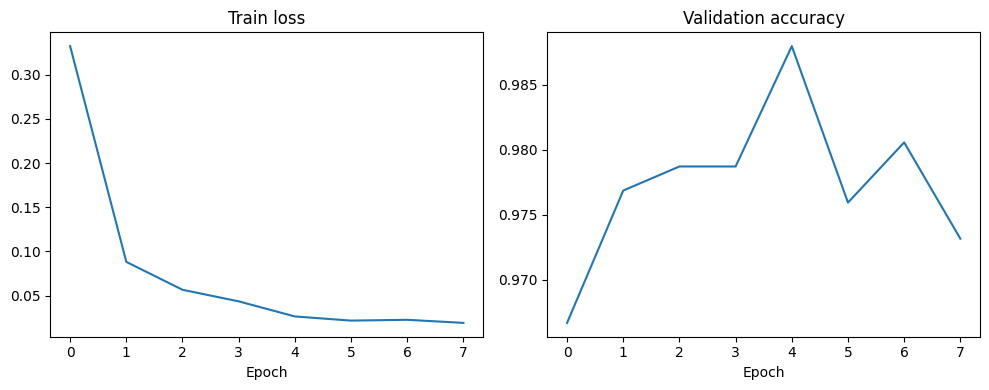

Модель сохранена: /content/drive/MyDrive/best.pth


In [ ]:
model = Model()
if not EVALUATE_ONLY:
    model.train(d_train)
    model.save('best')
else:
    #todo: your link goes here
    model.load('best')

Пример тестирования модели на части набора данных:

In [ ]:
# evaluating model on 10% of test dataset
pred_1 = model.test_on_dataset(d_test, limit=0.1)
Metrics.print_all(d_test.labels[:len(pred_1)], pred_1, '10% of test')

  0%|          | 0/3 [00:00<?, ?it/s]

metrics for 10% of test:
	 accuracy 0.9944:
	 balanced accuracy 0.9944:


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Пример тестирования модели на полном наборе данных:

In [ ]:
# evaluating model on full test dataset (may take time)
if TEST_ON_LARGE_DATASET:
    pred_2 = model.test_on_dataset(d_test)
    Metrics.print_all(d_test.labels, pred_2, 'test')

  0%|          | 0/29 [00:00<?, ?it/s]

metrics for test:
	 accuracy 0.9856:
	 balanced accuracy 0.9856:


In [ ]:
d_test_full = Dataset('test')

pred_full = model.test_on_dataset(d_test_full)
Metrics.print_all(d_test_full.labels, pred_full, 'full test')

Downloading...
From (original): https://drive.google.com/uc?id=1RfPou3pFKpuHDJZ-D9XDFzgvwpUBFlDr
From (redirected): https://drive.google.com/uc?id=1RfPou3pFKpuHDJZ-D9XDFzgvwpUBFlDr&confirm=t&uuid=c778e3ea-9d66-4a3f-a467-2dc7a394cdd0
To: /content/test.npz
100%|██████████| 525M/525M [00:08<00:00, 65.0MB/s]


Loading dataset test from npz.
Done. Dataset test consists of 4500 images.


  0%|          | 0/71 [00:00<?, ?it/s]

metrics for full test:
	 accuracy 0.9847:
	 balanced accuracy 0.9847:


              precision    recall  f1-score   support

         ADI       1.00      1.00      1.00       500
        BACK       1.00      1.00      1.00       500
         DEB       0.96      0.98      0.97       500
         LYM       1.00      1.00      1.00       500
         MUC       0.99      0.99      0.99       500
         MUS       0.98      0.98      0.98       500
        NORM       0.99      0.98      0.98       500
         STR       0.96      0.94      0.95       500
         TUM       0.98      0.99      0.98       500

    accuracy                           0.98      4500
   macro avg       0.98      0.98      0.98      4500
weighted avg       0.98      0.98      0.98      4500



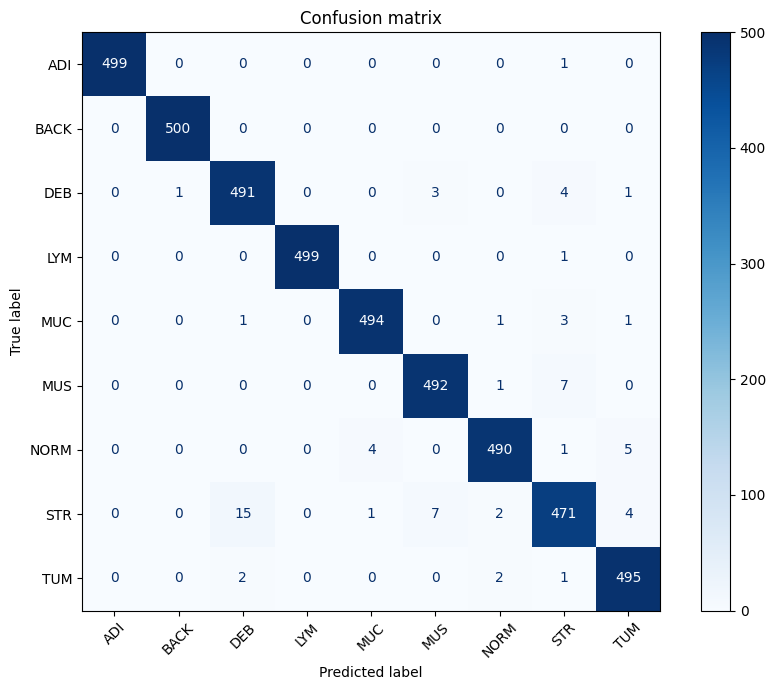

In [40]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

y_true = d_test_full.labels
y_pred = pred_full

# LBL7: матрица ошибок и метрики по классам
print(classification_report(y_true, y_pred, target_names=TISSUE_CLASSES))

cm = confusion_matrix(y_true, y_pred, labels=range(9))

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=TISSUE_CLASSES
).plot(ax=ax, cmap='Blues', xticks_rotation=45)

plt.title('Confusion matrix')
plt.tight_layout()
plt.show()

Результат работы пайплайна обучения и тестирования выше тоже будет оцениваться. Поэтому не забудьте присылать на проверку ноутбук с выполнеными ячейками кода с демонстрациями метрик обучения, графиками и т.п. В этом пайплайне Вам необходимо продемонстрировать работу всех реализованных дополнений, улучшений и т.п.

<font color="red">
Настоятельно рекомендуется после получения пайплайна с полными результатами обучения экспортировать ноутбук в pdf (файл -> печать) и прислать этот pdf вместе с самим ноутбуком.
</font>

### Тестирование модели на других наборах данных

Ваша модель должна поддерживать тестирование на других наборах данных. Для удобства, Вам предоставляется набор данных test_tiny, который представляет собой малую часть (2% изображений) набора test. Ниже приведен фрагмент кода, который будет осуществлять тестирование для оценивания Вашей модели на дополнительных тестовых наборах данных.

<font color="red">
Прежде чем отсылать задание на проверку, убедитесь в работоспособности фрагмента кода ниже.
</font>


In [ ]:
final_model = Model()
final_model.load('best')
d_test_tiny = Dataset('test_tiny')
pred = final_model.test_on_dataset(d_test_tiny)
Metrics.print_all(d_test_tiny.labels, pred, 'test-tiny')

Модель загружена


Downloading...
From: https://drive.google.com/uc?id=1viiB0s041CNsAK4itvX8PnYthJ-MDnQc
To: /content/test_tiny.npz
100%|██████████| 10.6M/10.6M [00:00<00:00, 50.6MB/s]


Loading dataset test_tiny from npz.
Done. Dataset test_tiny consists of 90 images.


  0%|          | 0/2 [00:00<?, ?it/s]

metrics for test-tiny:
	 accuracy 0.9778:
	 balanced accuracy 0.9778:
